In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python data science environment is ready!")
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)


Python data science environment is ready!
pandas version: 2.1.4
NumPy version: 1.26.4
Matplotlib version: 3.8.0


In [2]:

import pandas as pd

df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check column data types and non-missing values
print("\nDataset information:")
df.info()


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [4]:

# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check the target variable
print("\nChurn counts:")
print(df["Churn"].value_counts())


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [5]:

# Examine the TotalCharges column
print("Current data type:", df["TotalCharges"].dtype)

# Show a few values from the column
print("\nSample TotalCharges values:")
print(df["TotalCharges"].head(10).tolist())

# Count values that are empty or contain only whitespace
blank_total_charges = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("\nBlank TotalCharges values:", blank_total_charges)


Current data type: object

Sample TotalCharges values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']

Blank TotalCharges values: 11


In [6]:

# Convert TotalCharges from text to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Check the result
print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges values:", df["TotalCharges"].isna().sum())

# Inspect the affected customers
print("\nCustomers with missing TotalCharges:")
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])


TotalCharges data type: float64
Missing TotalCharges values: 11

Customers with missing TotalCharges:
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No


In [7]:

# Keep the original df unchanged and create a cleaned copy
df_clean = df.dropna(subset=["TotalCharges"]).copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Missing TotalCharges after cleaning:", df_clean["TotalCharges"].isna().sum())
print("Duplicate rows:", df_clean.duplicated().sum())


Original dataset shape: (7043, 21)
Cleaned dataset shape: (7032, 21)
Missing TotalCharges after cleaning: 0
Duplicate rows: 0


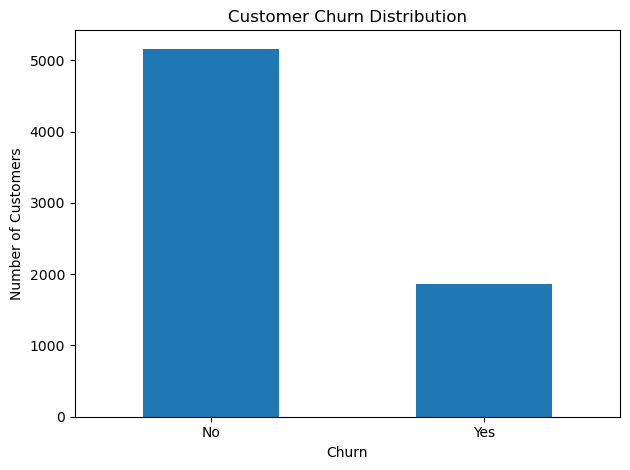

Churn rate: 26.58%


In [8]:

import matplotlib.pyplot as plt

# Count customers in each churn category
churn_counts = df_clean["Churn"].value_counts()

# Draw a bar chart
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Calculate the churn percentage
churn_rate = (df_clean["Churn"] == "Yes").mean() * 100

print(f"Churn rate: {churn_rate:.2f}%")


In [9]:

# Count customers by contract type and churn status
contract_counts = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

print("Customer counts by contract and churn:")
print(contract_counts)

# Calculate churn rate within each contract type
contract_churn_rate = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print("\nChurn rate by contract type (%):")
print(contract_churn_rate.round(2))


Customer counts by contract and churn:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48

Churn rate by contract type (%):
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


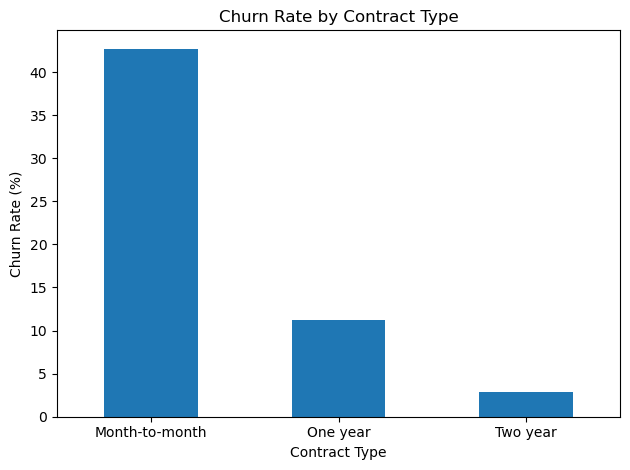

In [10]:

# Plot churn rates by contract type
contract_churn_rate["Yes"].plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [11]:

from scipy.stats import chi2_contingency
import numpy as np

observed = pd.crosstab(df_clean["Contract"], df_clean["Churn"])

chi2, p_value, dof, expected = chi2_contingency(observed)

# Check the expected cell counts assumption
print("Smallest expected cell count:", round(expected.min(), 2))
print("All expected counts >= 5:", (expected >= 5).all())

# Calculate Cramer's V
n = observed.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * min(observed.shape[0] - 1,
                                    observed.shape[1] - 1)))

print("\nChi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("P-value:", p_value)
print("Cramer's V:", round(cramers_v, 3))


Smallest expected cell count: 391.24
All expected counts >= 5: True

Chi-square statistic: 1179.546
Degrees of freedom: 2
P-value: 7.326182186265472e-257
Cramer's V: 0.41


In [12]:

# Check the target labels
print("Churn labels:")
print(df_clean["Churn"].value_counts())

# Inspect a few rows and selected columns
print("\nSelected columns:")
print(
    df_clean[
        ["tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]
    ].head()
)

# Check data types after cleaning
print("\nData types:")
print(df_clean[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].dtypes)


Churn labels:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Selected columns:
   tenure        Contract  MonthlyCharges  TotalCharges Churn
0       1  Month-to-month           29.85         29.85    No
1      34        One year           56.95       1889.50    No
2       2  Month-to-month           53.85        108.15   Yes
3      45        One year           42.30       1840.75    No
4       2  Month-to-month           70.70        151.65   Yes

Data types:
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
Churn              object
dtype: object


In [13]:

from sklearn.model_selection import train_test_split

# Remove customerID because it is an identifier, not a useful customer feature
X = df_clean.drop(columns=["Churn", "customerID"])

# Convert the target into 0 and 1
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\nTraining churn proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training rows: 5625
Testing rows: 1407

Training churn proportions:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64

Testing churn proportions:
Churn
0    0.734
1    0.266
Name: proportion, dtype: float64


In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns

# Preprocess numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Combine preprocessing with the classifier
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Pipeline created successfully.")
print("Numeric features:", list(numeric_features))
print("Categorical features:", list(categorical_features))


Pipeline created successfully.
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:

# Train the complete pipeline
model.fit(X_train, y_train)

print("Model training completed successfully!")

# Predict churn labels for unseen test customers
y_pred = model.predict(X_test)

# Predict churn probabilities
y_prob = model.predict_proba(X_test)[:, 1]

print("Number of predictions:", len(y_pred))
print("First 10 predicted labels:", y_pred[:10])
print("First 10 actual labels:", y_test.iloc[:10].to_list())
print("First 10 churn probabilities:", y_prob[:10].round(3))


Model training completed successfully!
Number of predictions: 1407
First 10 predicted labels: [0 1 0 0 0 0 0 0 1 0]
First 10 actual labels: [0, 0, 0, 1, 0, 1, 0, 0, 1, 0]
First 10 churn probabilities: [0.018 0.592 0.005 0.201 0.102 0.472 0.026 0.165 0.68  0.016]


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))


Accuracy: 0.805
Precision: 0.65
Recall: 0.575
F1-score: 0.61
ROC-AUC: 0.836

Confusion matrix:
[[917 116]
 [159 215]]

Classification report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1033
     Churned       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



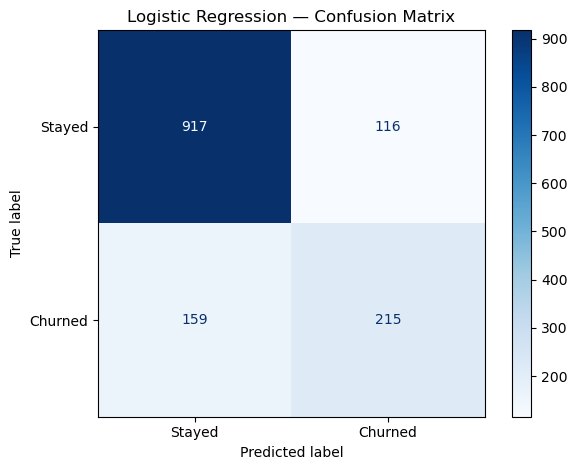

In [17]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


In [18]:

# Get the trained logistic regression model
classifier = model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Extract the fitted coefficients
coefficients = classifier.coef_[0]

# Put the feature names and coefficients into a table
coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Convert coefficients into odds ratios
coef_table["Odds_Ratio"] = np.exp(coef_table["Coefficient"])

# Display the strongest positive and negative coefficients
print("Features with the largest positive coefficients:")
print(
    coef_table.sort_values("Coefficient", ascending=False)
    .head(10)
    .round(3)
    .to_string(index=False)
)

print("\nFeatures with the largest negative coefficients:")
print(
    coef_table.sort_values("Coefficient")
    .head(10)
    .round(3)
    .to_string(index=False)
)


Features with the largest positive coefficients:
                            Feature  Coefficient  Odds_Ratio
       cat__Contract_Month-to-month        0.719       2.053
   cat__InternetService_Fiber optic        0.703       2.020
                  num__TotalCharges        0.641       1.899
               cat__StreamingTV_Yes        0.301       1.352
           cat__StreamingMovies_Yes        0.287       1.333
             cat__OnlineSecurity_No        0.270       1.310
cat__PaymentMethod_Electronic check        0.260       1.296
                cat__TechSupport_No        0.249       1.282
             cat__MultipleLines_Yes        0.183       1.201
               cat__OnlineBackup_No        0.149       1.161

Features with the largest negative coefficients:
                                  Feature  Coefficient  Odds_Ratio
                              num__tenure       -1.350       0.259
                   cat__Contract_Two year       -0.670       0.511
                      num__Mo

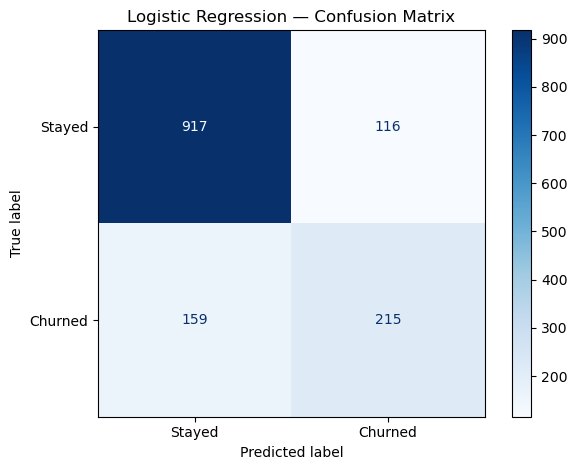

Chart saved as confusion_matrix.png


In [19]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved as confusion_matrix.png")


In [20]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Compare the default threshold with a lower threshold
for threshold in [0.5, 0.4]:
    predictions = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, predictions), 3))
    print("Recall:", round(recall_score(y_test, predictions), 3))
    print("F1-score:", round(f1_score(y_test, predictions), 3))



Threshold: 0.5
Precision: 0.65
Recall: 0.575
F1-score: 0.61

Threshold: 0.4
Precision: 0.579
Recall: 0.684
F1-score: 0.627
